# Credit Curve Construction & Spread Validation

> **What it does:** builds U.S. corporate credit curves by rating and maturity from the ICE BofA option-adjusted spread indices, bootstraps risk-neutral hazard rates and default probabilities from them, smooths and extends the maturity curve with a Gaussian process (with uncertainty bands), and runs the checks an independent price-verification or model-validation team applies to credit curves: rating monotonicity, term-structure shape, PCA of the spread history and anomaly detection on daily moves, plus a 40-year context from Moody's Baa spreads.
> **Data:** ICE BofA U.S. corporate and high-yield OAS by rating (AAA to CCC) and by maturity bucket (1–3 to 15+ years), last three years; Moody's Aaa and Baa yields since 1986 and the Treasury curve (all FRED).
> **Methods:** credit-triangle approximation and exact piecewise-constant hazard bootstrapping (CDS-style premium and protection legs, quarterly, 40% recovery); Gaussian-process regression with an RBF + white-noise kernel; rating-order and shape tests; PCA of log spreads; Isolation Forest on daily spread changes.
> **Key output:** today's credit curves and implied default probabilities by rating; the GP curve with its uncertainty; the data-quality and validation flags; and where today's spreads sit in history.

## 1. Why credit curves need their own validation

Every credit-sensitive valuation of a development bank uses a credit curve: the fair value of a corporate bond or loan, CVA on a swap, the hazard rates behind counterparty PFE limits, and the discounting of a guarantee. Most counterparties and obligors have no liquid bonds or CDS, so their curve is a **proxy**: an index curve for their rating and sector, shifted and interpolated. The validation questions are always the same:

1. Is the ordering right? A worse rating must never have a lower spread at the same maturity.
2. Is the term structure sensible, and how uncertain is it between and beyond the observed points?
3. Are the daily inputs clean, or are there stale or erroneous points?
4. What default probabilities does the curve imply, and are they plausible?

**Hazard rates.** With a constant hazard $\lambda$ and recovery $R$, a par CDS spread satisfies the *credit triangle* $s\approx\lambda(1-R)$. For a term structure, $\lambda(t)$ is taken piecewise constant between curve points and bootstrapped so that, at each maturity $T_k$, the premium leg $s_k\sum_i \Delta_i D(t_i)Q(t_i)$ equals the protection leg $(1-R)\sum_i D(t_i)\,[Q(t_{i-1})-Q(t_i)]$, with $Q(t)=e^{-\int_0^t\lambda}$ the survival probability. Bond OAS is used as a proxy for the CDS spread (ignoring the CDS–bond basis). These are **risk-neutral** probabilities: they include the credit risk premium and are far above historical default rates.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import) ---------------
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the kernel crashed".
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library ---------------------------------------------------------
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party ---------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
from scipy import optimize
from sklearn.ensemble import IsolationForest
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError("FRED_API_KEY not found. Create the .env file at the repo root (see .env.example).")
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0 Safari/537.36"}

SEED = 4
RECOVERY = 0.40
RATING_SERIES = {"AAA": "BAMLC0A1CAAA", "AA": "BAMLC0A2CAA", "A": "BAMLC0A3CA", "BBB": "BAMLC0A4CBBB",
                 "BB": "BAMLH0A1HYBB", "B": "BAMLH0A2HYB", "CCC & below": "BAMLH0A3HYC"}
MATURITY_SERIES = {2.0: "BAMLC1A0C13Y", 4.0: "BAMLC2A0C35Y", 6.0: "BAMLC3A0C57Y", 8.5: "BAMLC4A0C710Y",
                   12.5: "BAMLC7A0C1015Y", 20.0: "BAMLC8A0C15PY"}     # bucket mid-points (years)
IG_INDEX = "BAMLC0A0CM"
UST = {"DGS1": 1, "DGS2": 2, "DGS3": 3, "DGS5": 5, "DGS7": 7, "DGS10": 10, "DGS20": 20, "DGS30": 30}

print(f"run on {dt.date.today():%Y-%m-%d}")

run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours ----------
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if path.exists() and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours:
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(f"⚠️  {name}: download failed ({type(err).__name__}); using cached copy")
            return pd.read_parquet(path)
        raise


# --- Chart style -------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "lines.linewidth": 2.0, "font.size": 10, "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """Interactive HTML always; static PNG (for GitHub) when kaleido can find Chrome."""
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run `plotly_get_chrome` once.")


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

FRED carries the ICE BofA indices for the last three years only (a licensing restriction), so the long history uses Moody's seasoned Aaa and Baa corporate yields against the 10-year Treasury, available daily since 1986.

In [3]:
def fetch_fred(series, start=None):
    return pd.DataFrame({k: fred.get_series(v, observation_start=start) for k, v in series.items()})


rat = cached("ice_oas_rating", lambda: fetch_fred(RATING_SERIES).rename_axis("date").reset_index()).set_index("date").dropna(how="all")
mat = cached("ice_oas_maturity", lambda: fetch_fred({str(k): v for k, v in MATURITY_SERIES.items()}).rename_axis("date").reset_index()
             ).set_index("date").dropna(how="all")
mat.columns = [float(c) for c in mat.columns]
ig = fred.get_series(IG_INDEX).dropna()
ust = cached("ust_curve", lambda: fetch_fred({k: k for k in UST}, "2023-01-01").rename_axis("date").reset_index()).set_index("date").ffill()
moodys = cached("moodys_long", lambda: fetch_fred({"Aaa": "DAAA", "Baa": "DBAA", "UST10": "DGS10"}, "1986-01-01").rename_axis("date").reset_index()
                ).set_index("date").dropna()
EVAL = min(rat.dropna().index.max(), mat.dropna().index.max())
today_rat, today_mat = rat.loc[EVAL] * 100, mat.loc[EVAL] * 100        # basis points
print(f"ICE OAS {rat.index.min():%Y-%m-%d} → {EVAL:%Y-%m-%d} ({len(rat)} days) · Moody's daily since {moodys.index.min():%Y}")
pd.DataFrame({"OAS today (bp)": today_rat, "3y min": rat.min() * 100, "3y median": rat.median() * 100, "3y max": rat.max() * 100}).round(0)

ICE OAS 2023-10-20 → 2026-10-16 (784 days) · Moody's daily since 1986


,OAS today (bp),3y min,3y median,3y max
AAA,41.00,27.00,36.00,59.00
AA,61.00,41.00,50.00,73.00
A,71.00,59.00,70.00,115.00
BBB,106.00,92.00,106.00,163.00
BB,203.00,150.00,182.00,311.00
B,335.00,254.00,304.00,486.00
CCC & below,"1,297.00",690.00,908.00,"1,297.00"


## 4. Hazard rates and default probabilities by rating

Rating curves have one point each (the all-maturity index), so each rating's term structure is taken as its index level times the shape of the investment-grade maturity curve, normalised to the IG index level. This is a common proxy construction; its weakness (the same shape for AAA and CCC) is discussed below. Hazards are then bootstrapped exactly at the bucket maturities with Treasury discounting.

In [4]:
ust_today = ust.loc[:EVAL].iloc[-1]
ust_t, ust_y = np.array(list(UST.values()), float), ust_today[list(UST)].to_numpy() / 100


def disc(t):
    return np.exp(-np.interp(t, ust_t, ust_y) * t)            # par ≈ zero yields; small error for this purpose


def bootstrap_hazards(mats, spreads_bp, R=RECOVERY, dt_=0.25):
    """Piecewise-constant hazard rates matching par CDS-style spreads at each maturity."""
    lam, knots = [], [0.0]
    for T, s in zip(mats, np.asarray(spreads_bp) / 1e4):
        def gap(l):
            grid = np.arange(dt_, T + 1e-9, dt_)
            hz = np.array([lam[np.searchsorted(knots[1:], u, side="left")] if u <= knots[-1] else l for u in grid])
            Q = np.exp(-np.cumsum(hz * dt_))
            Qprev = np.concatenate([[1.0], Q[:-1]])
            D = disc(grid)
            return s * np.sum(dt_ * D * Q) - (1 - R) * np.sum(D * (Qprev - Q))
        lam.append(optimize.brentq(gap, 1e-8, 5.0))
        knots.append(T)
    return np.array(lam), np.array(knots[1:])


mats = np.array(list(MATURITY_SERIES))
shape = today_mat.to_numpy() / (ig.loc[:EVAL].iloc[-1] * 100)
curves, pds = {}, {}
for r_, s in today_rat.items():
    spreads = s * shape
    lam, knots = bootstrap_hazards(mats, spreads)
    curves[r_] = pd.Series(spreads, index=mats)
    surv = lambda T: np.exp(-np.sum(np.diff(np.concatenate([[0], np.minimum(knots, T)])) * lam))
    pds[r_] = {"OAS (bp)": s, "credit-triangle λ (%)": s / 1e4 / (1 - RECOVERY) * 100, "bootstrapped λ 0–2y (%)": lam[0] * 100,
               "1y PD (%)": (1 - surv(1)) * 100, "5y cumulative PD (%)": (1 - surv(5)) * 100, "10y cumulative PD (%)": (1 - surv(10)) * 100}
pd_tab = pd.DataFrame(pds).T
curve_tab = pd.DataFrame(curves).T.round(0)
curve_tab.columns = [f"{c:g}y" for c in curve_tab.columns]
display(curve_tab)
pd_tab.round(2)

,2y,4y,6y,8.5y,12.5y,20y
AAA,27.00,36.00,42.00,50.00,50.00,50.00
AA,39.00,54.00,63.00,75.00,75.00,75.00
A,46.00,63.00,74.00,87.00,87.00,87.00
BBB,69.00,94.00,110.00,130.00,130.00,130.00
BB,131.00,179.00,210.00,248.00,248.00,248.00
B,217.00,296.00,347.00,410.00,410.00,410.00
CCC & below,839.00,"1,144.00","1,343.00","1,587.00","1,587.00","1,587.00"


,OAS (bp),credit-triangle λ (%),bootstrapped λ 0–2y (%),1y PD (%),5y cumulative PD (%),10y cumulative PD (%)
AAA,41.00,0.68,0.44,0.44,3.35,8.33
AA,61.00,1.02,0.66,0.66,4.94,12.17
A,71.00,1.18,0.76,0.76,5.73,14.04
BBB,106.00,1.77,1.14,1.14,8.45,20.31
BB,203.00,3.38,2.18,2.16,15.64,35.69
B,335.00,5.58,3.60,3.53,24.64,52.58
CCC & below,"1,297.00",21.62,13.75,12.85,69.86,99.78


## 5. A Gaussian-process curve with uncertainty

The six IG maturity buckets are noisy point estimates at bucket mid-points. A Gaussian process with an RBF kernel (smooth curve) plus white noise (observation error), fitted on log maturity around a linear trend in log maturity (so that it extrapolates along the trend rather than back to the average), interpolates between buckets and, more importantly, says how uncertain the curve is between and beyond them. The fit uses the last 20 business days' bucket spreads as repeated observations, so the noise level is learned from the data.

In [5]:
recent = mat.loc[:EVAL].tail(20) * 100
Xg = np.log(np.repeat(mats, len(recent))).reshape(-1, 1)
yg = recent.to_numpy().T.ravel()
trend = np.polyfit(Xg.ravel(), yg, 1)                     # linear trend in log maturity: the prior mean of the curve
resid = yg - np.polyval(trend, Xg.ravel())
kernel = ConstantKernel(1.0) * RBF(length_scale=1.0, length_scale_bounds=(0.6, 10)) + WhiteKernel(1.0, (1e-3, 1e3))
from sklearn.exceptions import ConvergenceWarning
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)                # length scale sits at its 0.6 floor (smoothness prior)
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=5, random_state=SEED).fit(Xg, resid)


def gp_curve(t):
    m, sd = gp.predict(np.log(t).reshape(-1, 1), return_std=True)
    return m + np.polyval(trend, np.log(t)), sd


grid_t = np.linspace(0.5, 30, 120)
g_mu, g_sd = gp_curve(grid_t)
noise_sd = np.sqrt(gp.kernel_.k2.noise_level) * resid.std()
check = pd.DataFrame({"maturity (y)": [1, 3, 5, 7, 10, 15, 25, 30]})
mu_c, sd_c = gp_curve(check["maturity (y)"].to_numpy(float))
check["GP spread (bp)"], check["± 2 s.d. (bp)"] = mu_c, 2 * sd_c
print(f"Fitted kernel: {gp.kernel_} · observation noise ≈ {noise_sd:.1f} bp")
check.round(1).set_index("maturity (y)")

Fitted kernel: 2.85**2 * RBF(length_scale=0.6) + WhiteKernel(noise_level=0.202) · observation noise ≈ 3.0 bp


,GP spread (bp),± 2 s.d. (bp)
maturity (y),,
1,32.50,29.90
3,66.90,7.10
5,77.40,6.10
7,92.80,6.00
10,102.50,6.00
15,98.10,6.20
25,109.60,9.00
30,118.40,15.70


## 6. Validation checks

1. **Rating monotonicity:** on how many days does a better rating show a wider spread than the next rating down?
2. **Term-structure shape:** on how many days is the IG curve inverted (short bucket above the long one), and where is today's curve flat?
3. **PCA of log spreads by rating:** how many factors drive the curve family?
4. **Anomaly detection:** an Isolation Forest on daily changes of all 13 series flags the most unusual days; each flagged day is classified as *market-wide* (most series move together) or *idiosyncratic* (one series moves alone), which is the signature of a bad input.

In [6]:
order = list(RATING_SERIES)
inv = pd.DataFrame({f"{a} > {b}": (rat[a] > rat[b]) for a, b in zip(order[:-1], order[1:])})
mono = pd.DataFrame({"days inverted": inv.sum(), "share %": inv.mean() * 100, "max gap (bp)": [
    ((rat[a] - rat[b]).clip(lower=0) * 100).max() for a, b in zip(order[:-1], order[1:])]})
shape_flags = pd.Series({"days 1–3y above 15y+": int((mat[2.0] > mat[20.0]).sum()),
                         "days 7–10y above 15y+": int((mat[8.5] > mat[20.0]).sum()),
                         "today 7–10y vs 15y+ (bp)": (today_mat[8.5] - today_mat[20.0]),
                         "today 10–15y vs 15y+ (bp)": (today_mat[12.5] - today_mat[20.0])})

logs = np.log(rat.dropna())
Z = (logs - logs.mean()) / logs.std()
ev, evec = np.linalg.eigh(np.cov(Z.T))
ev, evec = ev[::-1], evec[:, ::-1]
pca = pd.DataFrame(evec[:, :3], index=order, columns=["PC1", "PC2", "PC3"])
pca.loc["variance explained %"] = ev[:3] / ev.sum() * 100

chg = pd.concat([rat, mat], axis=1).dropna().diff().dropna() * 100
chg.columns = [str(c) for c in chg.columns]
iso = IsolationForest(n_estimators=500, contamination=0.01, random_state=SEED).fit(chg)
score = -iso.score_samples(chg)
flag = chg[iso.predict(chg) == -1]
robust = (chg - chg.median()) / (chg.abs().median() * 1.4826 + 1e-9)
flags = pd.DataFrame({"largest move (series)": robust.loc[flag.index].abs().idxmax(axis=1),
                      "largest move (bp)": [chg.loc[d, robust.loc[d].abs().idxmax()] for d in flag.index],
                      "series moving > 3 robust s.d.": (robust.loc[flag.index].abs() > 3).sum(axis=1),
                      "BBB change (bp)": chg.loc[flag.index, "BBB"]})
flags["type"] = np.where(flags["series moving > 3 robust s.d."] >= 5, "market-wide", "idiosyncratic: check input")
display(mono.round(1)); display(shape_flags.round(1).to_frame("value")); display(pca.round(3))
flags.round(1)

,days inverted,share %,max gap (bp)
AAA > AA,0,0.00,0.00
AA > A,0,0.00,0.00
A > BBB,0,0.00,0.00
BBB > BB,0,0.00,0.00
BB > B,0,0.00,0.00
B > CCC & below,0,0.00,0.00


,value
days 1–3y above 15y+,0.00
days 7–10y above 15y+,287.00
today 7–10y vs 15y+ (bp),0.00
today 10–15y vs 15y+ (bp),0.00


,PC1,PC2,PC3
AAA,-0.37,-0.37,-0.46
AA,-0.39,-0.37,-0.28
A,-0.41,0.28,-0.27
BBB,-0.40,0.34,-0.16
BB,-0.40,0.33,0.24
B,-0.39,0.18,0.54
CCC & below,-0.28,-0.62,0.52
variance explained %,73.06,16.49,6.63


,largest move (series),largest move (bp),series moving > 3 robust s.d.,BBB change (bp),type
date,,,,,
2023-12-14,CCC & below,-50.00,7,-4.00,market-wide
2024-08-02,CCC & below,57.00,12,7.00,market-wide
2024-08-05,CCC & below,45.00,13,7.00,market-wide
2024-08-06,BB,-22.00,7,-5.00,market-wide
2025-04-03,CCC & below,93.00,13,11.00,market-wide
2025-04-04,CCC & below,81.00,13,11.00,market-wide
2025-04-07,2.0,10.00,7,7.00,market-wide
2025-05-12,BB,-33.00,9,-7.00,market-wide


## 7. Forty years of context

Moody's Baa yield minus the 10-year Treasury is the longest daily credit-spread series available. Today's level is placed in its historical distribution together with the crisis peaks.

In [7]:
baa = (moodys["Baa"] - moodys["UST10"]) * 100
aaa = (moodys["Aaa"] - moodys["UST10"]) * 100
ctx = pd.DataFrame({"Baa − UST10 (bp)": baa, "Aaa − UST10 (bp)": aaa})
now = ctx.iloc[-1]
pct = {c: (ctx[c] < now[c]).mean() * 100 for c in ctx}
peaks = {"1990–91": ("1990-01-01", "1991-12-31"), "2001–02": ("2001-01-01", "2002-12-31"), "2008–09": ("2008-01-01", "2009-12-31"),
         "2020": ("2020-01-01", "2020-12-31"), "2022": ("2022-01-01", "2022-12-31")}
peak_tab = pd.DataFrame({k: ctx.loc[a:b].max() for k, (a, b) in peaks.items()}).T
peak_tab.loc["today"] = now
peak_tab.loc["today's percentile since 1986"] = pd.Series(pct)
peak_tab.round(0)

,Baa − UST10 (bp),Aaa − UST10 (bp)
1990–91,245.00,145.00
2001–02,390.00,267.00
2008–09,616.00,300.00
2020,431.00,320.00
2022,242.00,155.00
today,146.00,97.00
today's percentile since 1986,3.00,27.00


## 8. Charts

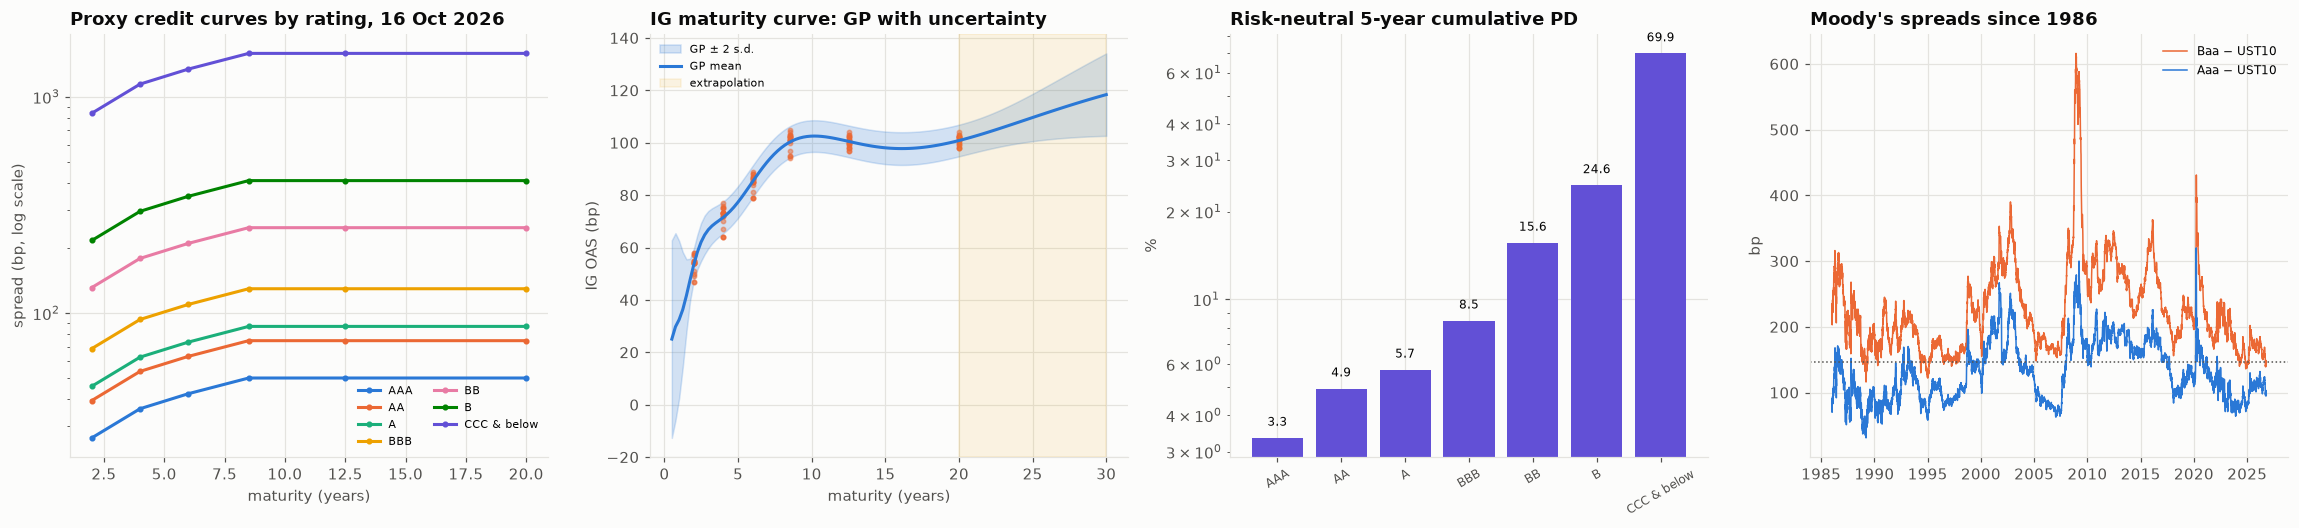

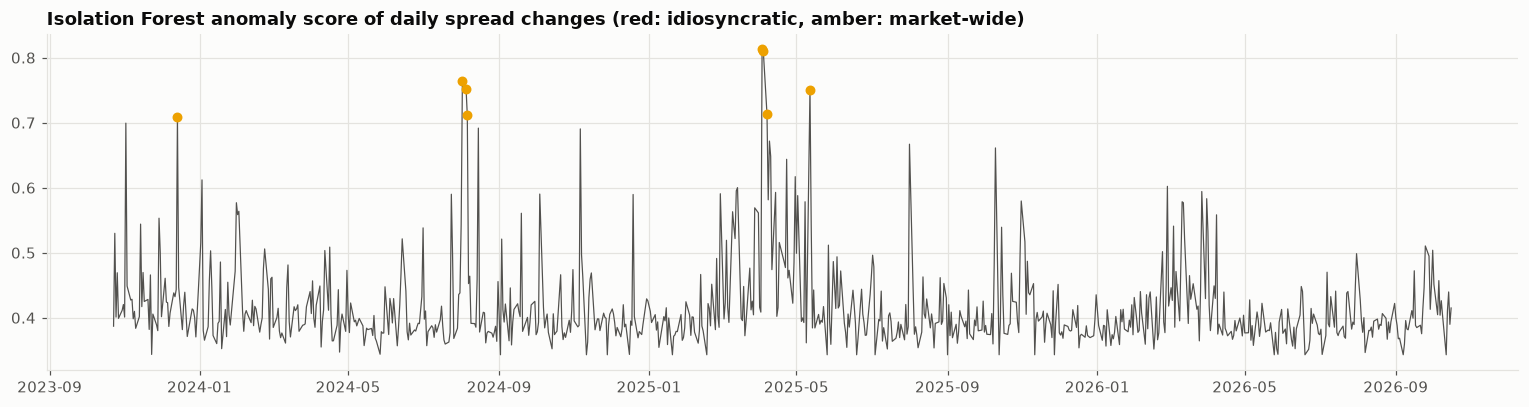

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.9))
ax = axes[0]
for (r_, s), col in zip(curves.items(), PALETTE):
    ax.plot(s.index, s.values, "o-", ms=3, color=col, label=r_)
ax.set_yscale("log"); ax.set_xlabel("maturity (years)"); ax.set_ylabel("spread (bp, log scale)")
ax.set_title(f"Proxy credit curves by rating, {EVAL:%d %b %Y}"); ax.legend(fontsize=7, ncol=2)
ax = axes[1]
ax.fill_between(grid_t, g_mu - 2 * g_sd, g_mu + 2 * g_sd, color=PALETTE[0], alpha=0.2, label="GP ± 2 s.d.")
ax.plot(grid_t, g_mu, color=PALETTE[0], label="GP mean")
for k in range(len(mats)):
    ax.scatter(np.full(len(recent), mats[k]), recent.iloc[:, k], s=8, color=PALETTE[1], alpha=0.5)
ax.axvspan(20, 30, color=STATUS["amber"], alpha=0.1, label="extrapolation")
ax.set_xlabel("maturity (years)"); ax.set_ylabel("IG OAS (bp)"); ax.set_title("IG maturity curve: GP with uncertainty"); ax.legend(fontsize=7)
ax = axes[2]
ax.bar(pd_tab.index, pd_tab["5y cumulative PD (%)"], color=PALETTE[6])
ax.set_yscale("log"); ax.set_ylabel("%"); ax.set_title("Risk-neutral 5-year cumulative PD"); ax.tick_params(axis="x", rotation=30, labelsize=8)
for i, v in enumerate(pd_tab["5y cumulative PD (%)"]):
    ax.text(i, v * 1.1, f"{v:.1f}", ha="center", fontsize=8)
ax = axes[3]
ax.plot(ctx.index, ctx["Baa − UST10 (bp)"], color=PALETTE[1], lw=1, label="Baa − UST10")
ax.plot(ctx.index, ctx["Aaa − UST10 (bp)"], color=PALETTE[0], lw=1, label="Aaa − UST10")
ax.axhline(now["Baa − UST10 (bp)"], color=INK_2, ls=":", lw=1)
ax.set_title("Moody's spreads since 1986"); ax.set_ylabel("bp"); ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_curves_gp_pd_history")
plt.show()

fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(chg.index, score, color=INK_2, lw=0.8)
for d, r_ in flags.iterrows():
    ax.scatter(d, score[chg.index.get_loc(d)], color=STATUS["red"] if r_["type"].startswith("idio") else STATUS["amber"], s=30, zorder=3)
ax.set_title("Isolation Forest anomaly score of daily spread changes (red: idiosyncratic, amber: market-wide)")
plt.tight_layout()
save_fig(fig, "02_anomaly_scores")
plt.show()

## 9. Reading the results and limitations

ICE BofA U.S. corporate OAS, 20 October 2023 – 16 October 2026, with Moody's spreads since 1986 for context:

- **Investment grade is near its tightest in 40 years; CCC is at its widest in three.** BBB trades at 106 bp and the IG maturity curve rises from 55 bp (1–3 years) to 104 bp (7 years and beyond). Moody's Baa – 10-year Treasury spread is 146 bp, the **3rd percentile** since 1986, against peaks of 616 bp in 2008–09 and 431 bp in 2020. At the bottom of the scale, CCC and below is at **1,297 bp**, its three-year high (median 908 bp), while BB and B are only moderately above their medians. Stress is concentrated in the weakest credits rather than spread across the market. This kind of divergence is exactly what a single "credit spread" factor in a risk model would miss.
- **Rating order holds every day.** Across 784 days and six adjacent pairs, no better rating ever had a wider spread than the next one down. The index curves pass the most basic validation test with no exceptions.
- **The long end is often humped or flat.** The 7–10-year bucket was above the 15-year-plus bucket on 287 days (37%). Today the 7–10, 10–15 and 15+ buckets are all at 104 bp. Seven days in the sample show three identical buckets, a consequence of FRED's 1 bp rounding, not stale data. Interpolating a monotone curve through these points would invent a slope that the market does not show.
- **The Gaussian process quantifies interpolation risk.** Observation noise is about 3 bp. Inside the observed range (3–15 years) the 95% band is ±6–7 bp. It widens to ±9 bp at 25 years, ±16 bp at 30 years and ±30 bp at 1 year, below the shortest bucket mid-point. Beyond the data the GP follows its prior mean, here a linear trend in log maturity. The 30-year point therefore comes out at 118 bp although the observed long end is flat at about 104 bp. Without the trend, an earlier version reverted to the average and bent *upward* at 1 year. The choice of prior drives the extrapolated tenors, which is the model risk a validator should size. For a proxy curve used in CVA or fair value, the GP band is a ready-made **model-uncertainty reserve** for those tenors.
- **Implied default probabilities are risk-neutral and large.** With 40% recovery, the five-year cumulative risk-neutral PD is 3.4% for AAA, 8.5% for BBB, 16% for BB, 25% for B and 70% for CCC. Ten-year values are 8% (AAA) to almost 100% (CCC). These are several times historical default experience, because spreads also pay for liquidity and the credit risk premium. They are the right numbers for pricing and CVA, and the wrong ones for provisioning or capital, which need real-world PDs. Bootstrapped short-end hazards are about 35% below the credit triangle applied to the index level, because the short end of the curve is far below the all-maturity average.
- **The proxy construction has a visible weakness.** Every rating curve is the IG maturity shape scaled to its index level, so CCC is given a steep upward curve (839 bp at 2 years to 1,587 bp at 20). Distressed curves are usually flat or inverted, because default risk is front-loaded. A production proxy would use rating-specific shapes (from CDS or bond-level data) or at least invert the HY curve. That is the main validation finding against this method.
- **Three factors explain the curve family.** On log spreads, PC1 (all ratings together) explains 73% of the variance. PC2 (16%) opposes CCC to the BBB–B middle, the dispersion trade visible today. PC3 (7%) is a quality slope, AAA/AA against B/CCC.
- **The anomaly screen finds market events, not bad data.** The Isolation Forest flags 8 days, all market-wide, with 7–13 of 13 series moving more than three robust standard deviations: 14 December 2023 (the Fed's pivot rally); 2–6 August 2024 (the yen carry-trade unwind); 3–7 April 2025 (the tariff shock, CCC +93 bp in a day); and 12 May 2025 (the U.S.–China tariff truce). No day looks like an isolated bad input, which is the result an independent price-verification process wants to document.

**Limitations**

- OAS on bond indices is not CDS: it includes the bond-CDS basis and liquidity premia, and index composition changes over time (fallen angels move between IG and HY).
- Only three years of ICE history are available on FRED; the long-run context relies on Moody's seasoned Aaa/Baa yields, which are long-maturity averages.
- Discounting uses Treasury par yields as zero rates and a flat 40% recovery for all ratings.

In [9]:
curve_tab.to_csv(OUT_DIR / "proxy_curves_by_rating_bp.csv")
pd_tab.to_csv(OUT_DIR / "hazard_rates_and_pds.csv")
check.to_csv(OUT_DIR / "gp_curve_check_points.csv", index=False)
mono.to_csv(OUT_DIR / "rating_monotonicity.csv")
flags.to_csv(OUT_DIR / "anomaly_flags.csv")
peak_tab.to_csv(OUT_DIR / "long_history_context.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_curves_gp_pd_history.png, 02_anomaly_scores.png, anomaly_flags.csv, gp_curve_check_points.csv, hazard_rates_and_pds.csv, long_history_context.csv, proxy_curves_by_rating_bp.csv, rating_monotonicity.csv
